Starting UAV Strategy Engine Genetic Algorithm Optimization...
Optimization Finished! Best Fitness Achieved: -2119.92


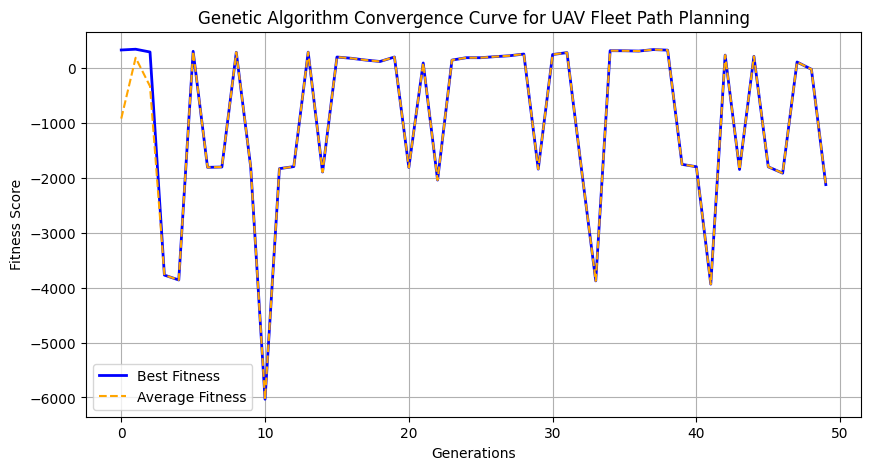

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

class HazardGrid:
    """Represents the 2D disaster management operational grid space."""
    def __init__(self, size=50, obstacle_density=0.1):
        self.size = size
        self.grid = np.zeros((size, size)) # 0: open space, 1: obstacle/no-fly zone
        self.hazard_map = np.random.uniform(0.1, 1.0, (size, size)) # Environmental risk weights
        self._initialize_obstacles(obstacle_density)

    def _initialize_obstacles(self, density):
        num_obstacles = int(self.size * self.size * density)
        for _ in range(num_obstacles):
            x = random.randint(0, self.size - 1)
            y = random.randint(0, self.size - 1)
            self.grid[x, y] = 1 # Mark as blocked

class UAVChromosome:
    """Encodes a drone's flight path, speed, and sensor profile."""
    def __init__(self, num_waypoints=6, grid_size=50):
        self.grid_size = grid_size
        self.path = []
        for _ in range(num_waypoints):
            x = random.uniform(0, grid_size - 1)
            y = random.uniform(0, grid_size - 1)
            speed = random.uniform(1.0, 10.0)
            sensor_state = random.choice([0, 1])
            self.path.append([x, y, speed, sensor_state])
        self.fitness = 0.0

    def evaluate(self, environment):
        energy_spent = 0.0
        hazard_exposure = 0.0
        penalty = 0.0
        coverage = 0

        prev_point = self.path[0]
        for point in self.path[1:]:
            dist = np.sqrt((point[0] - prev_point[0])**2 + (point[1] - prev_point[1])**2)
            # Energy proportional to distance traveled and velocity squared
            energy_spent += dist * (point[2] ** 2)

            gx, gy = int(np.clip(point[0], 0, environment.size - 1)), int(np.clip(point[1], 0, environment.size - 1))

            if environment.grid[gx, gy] == 1:
                penalty += 2000.0 # Heavy penalty for hitting a no-fly zone / obstacle
            else:
                hazard_exposure += environment.hazard_map[gx, gy]
                if point[3] == 1:
                    coverage += 1 # Reward for active sensor surveillance in safe zone

            prev_point = point

        # Multi-objective fitness formula (Maximize coverage, Minimize energy & hazards)
        self.fitness = (coverage * 100.0) - (energy_spent * 0.05) - (hazard_exposure * 10.0) - penalty

class UAVGeneticAlgorithm:
    """Manages population evolution, selection, crossover, and mutation."""
    def __init__(self, pop_size=50, generations=60, mutation_rate=0.15):
        self.pop_size = pop_size
        self.generations = generations
        self.mutation_rate = mutation_rate
        self.env = HazardGrid(size=50)
        self.population = [UAVChromosome(grid_size=50) for _ in range(pop_size)]
        self.best_fitness_history = []
        self.avg_fitness_history = []

    def run(self):
        for gen in range(self.generations):
            for ind in self.population:
                ind.evaluate(self.env)

            # Sort population by fitness descending
            self.population.sort(key=lambda x: x.fitness, reverse=True)

            best_fit = self.population[0].fitness
            avg_fit = np.mean([ind.fitness for ind in self.population])

            self.best_fitness_history.append(best_fit)
            self.avg_fitness_history.append(avg_fit)

            # Elitism: carry over top 10% best solutions
            new_pop = self.population[:int(self.pop_size * 0.1)]

            while len(new_pop) < self.pop_size:
                parent1 = self.select_parent()
                parent2 = self.select_parent()
                child = self.crossover(parent1, parent2)
                self.mutate(child)
                new_pop.append(child)

            self.population = new_pop

    def select_parent(self):
        # Tournament selection with size 5
        tournament = random.sample(self.population[:30], 5)
        return max(tournament, key=lambda x: x.fitness)

    def crossover(self, p1, p2):
        child = UAVChromosome(grid_size=self.env.size)
        split = len(p1.path) // 2
        child.path = p1.path[:split] + p2.path[split:]
        return child

    def mutate(self, ind):
        for point in ind.path:
            if random.random() < self.mutation_rate:
                point[0] = np.clip(point[0] + random.gauss(0, 1.5), 0, self.env.size - 1)
                point[1] = np.clip(point[1] + random.gauss(0, 1.5), 0, self.env.size - 1)
                point[2] = np.clip(point[2] + random.gauss(0, 0.5), 1.0, 10.0)

# --- Execution in Colab ---
if __name__ == "__main__":
    print("Starting UAV Strategy Engine Genetic Algorithm Optimization...")
    ga = UAVGeneticAlgorithm(pop_size=50, generations=50)
    ga.run()
    print(f"Optimization Finished! Best Fitness Achieved: {ga.best_fitness_history[-1]:.2f}")

    # Plotting Convergence Curve inline in Colab
    plt.figure(figsize=(10, 5))
    plt.plot(ga.best_fitness_history, label="Best Fitness", color="blue", linewidth=2)
    plt.plot(ga.avg_fitness_history, label="Average Fitness", color="orange", linestyle="--")
    plt.title("Genetic Algorithm Convergence Curve for UAV Fleet Path Planning")
    plt.xlabel("Generations")
    plt.ylabel("Fitness Score")
    plt.legend()
    plt.grid(True)
    plt.savefig("convergence_curve.png") # Saves a copy to your Colab session files
    plt.show()